# Food Delivery Status Prediction using Logistic Regression

**Objective:** Predict whether a food delivery will be "Fast" or "Delayed" (based on the median delivery time) using order, weather, traffic, and rating features, with Logistic Regression and hyperparameter tuning.

## 1. Data Cleaning
Checking for missing values and duplicate rows, and removing them if present.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve, auc
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import LabelEncoder, StandardScaler

df = pd.read_csv("/content/drive/MyDrive/Food_Delivery_Time_Prediction.csv")

print("Missing values per column:")
print(df.isnull().sum())

print(f"\nDuplicate rows: {df.duplicated().sum()}")
df = df.drop_duplicates()
df = df.dropna()

print(f"\nShape after cleaning: {df.shape}")

Missing values per column:
Order_ID                      0
Customer_Location             0
Restaurant_Location           0
Distance                      0
Weather_Conditions            0
Traffic_Conditions            0
Delivery_Person_Experience    0
Order_Priority                0
Order_Time                    0
Vehicle_Type                  0
Restaurant_Rating             0
Customer_Rating               0
Delivery_Time                 0
Order_Cost                    0
Tip_Amount                    0
dtype: int64

Duplicate rows: 0

Shape after cleaning: (200, 15)


## 2. Exploratory Data Analysis (EDA)
Examining the distribution of numeric features, checking for outliers, and visualizing how delivery time varies across traffic, weather, and vehicle type.


Summary statistics:
         Distance  Delivery_Person_Experience  Restaurant_Rating  \
count  200.000000                  200.000000         200.000000   
mean    11.498050                    5.250000           3.738500   
std      6.841755                    2.745027           0.703021   
min      0.520000                    1.000000           2.500000   
25%      6.090000                    3.000000           3.200000   
50%     10.265000                    5.000000           3.800000   
75%     16.497500                    8.000000           4.300000   
max     24.900000                   10.000000           5.000000   

       Customer_Rating  Delivery_Time   Order_Cost  Tip_Amount  
count       200.000000     200.000000   200.000000  200.000000  
mean          3.686500      70.494950  1046.488700   46.616650  
std           0.697063      29.830694   548.568922   29.361706  
min           2.600000      15.230000   122.300000    1.240000  
25%           3.100000      46.997500   5

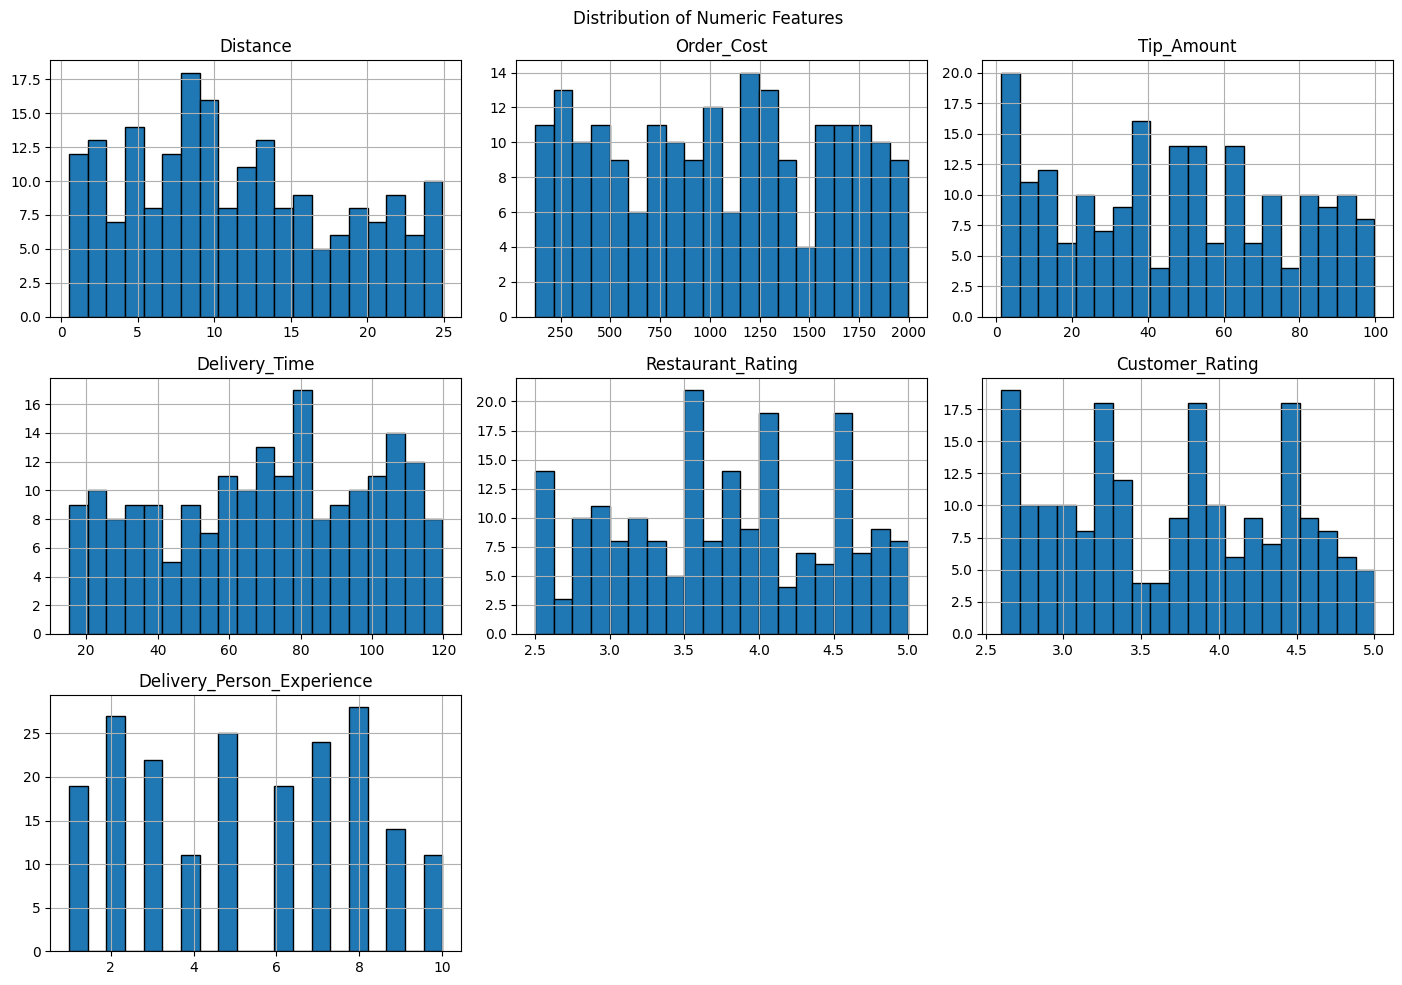

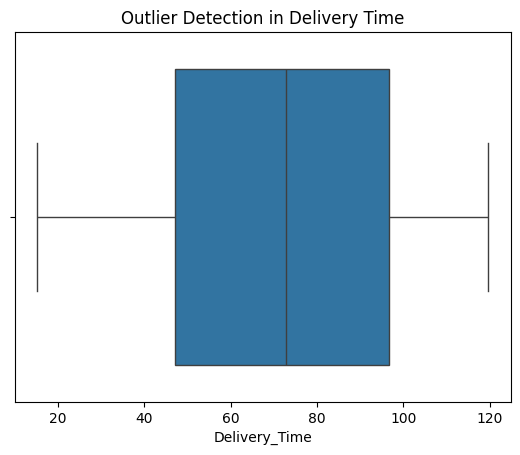

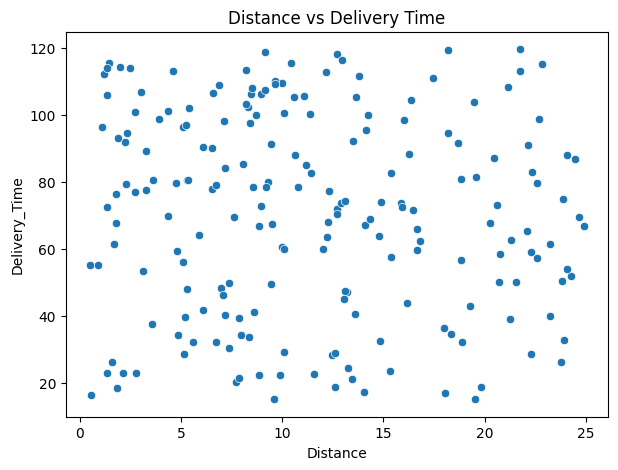

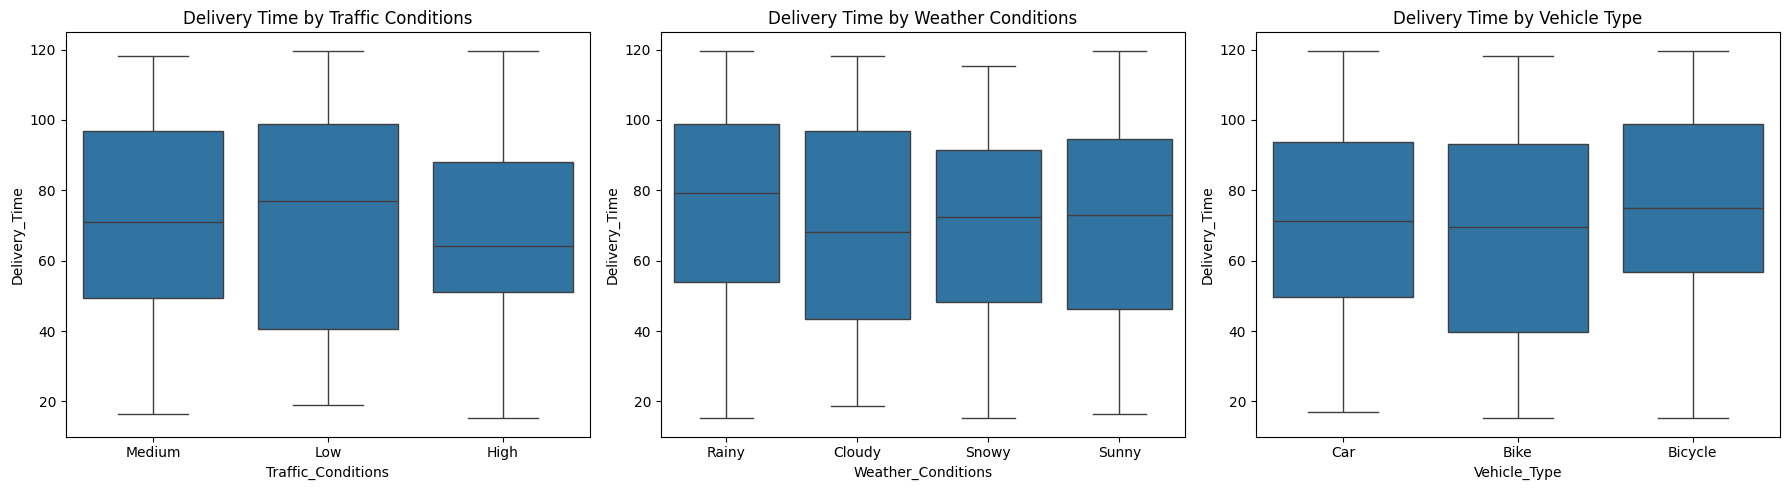

In [ ]:
print("\nSummary statistics:")
print(df.describe())

numeric_cols = ['Distance', 'Order_Cost', 'Tip_Amount', 'Delivery_Time',
                 'Restaurant_Rating', 'Customer_Rating', 'Delivery_Person_Experience']

df[numeric_cols].hist(figsize=(14, 10), bins=20, edgecolor='black')
plt.suptitle("Distribution of Numeric Features")
plt.tight_layout()
plt.show()

sns.boxplot(x=df['Delivery_Time'])
plt.title('Outlier Detection in Delivery Time')
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x=df['Distance'], y=df['Delivery_Time'])
plt.title('Distance vs Delivery Time')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(x=df['Traffic_Conditions'], y=df['Delivery_Time'], ax=axes[0])
axes[0].set_title('Delivery Time by Traffic Conditions')
sns.boxplot(x=df['Weather_Conditions'], y=df['Delivery_Time'], ax=axes[1])
axes[1].set_title('Delivery Time by Weather Conditions')
sns.boxplot(x=df['Vehicle_Type'], y=df['Delivery_Time'], ax=axes[2])
axes[2].set_title('Delivery Time by Vehicle Type')
plt.tight_layout()
plt.show()

## 3. Encoding & Feature Scaling
Encoding categorical columns (nominal columns via Label Encoding, `Order_Priority` via manual ordinal mapping since it has a real Low < Medium < High order), then scaling numeric features and reviewing the correlation heatmap.

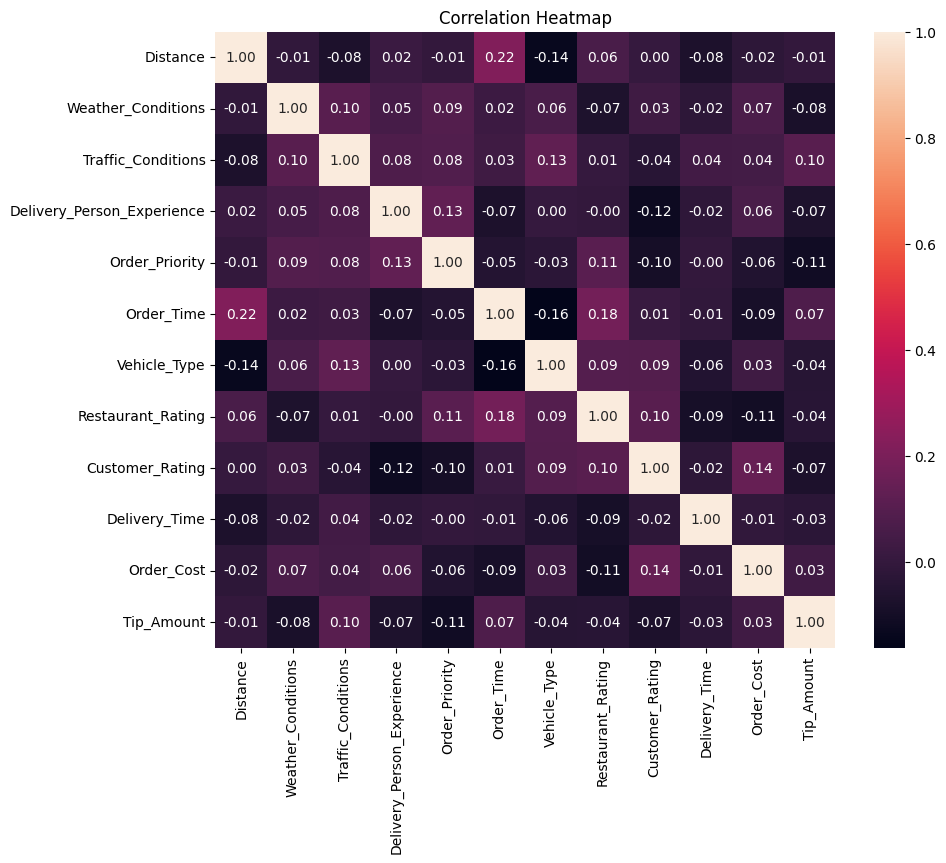

In [ ]:
# One LabelEncoder per column, stored in a dict (needed later for deployment)
encoders = {}
col = ['Weather_Conditions', 'Traffic_Conditions', 'Vehicle_Type', 'Order_Time']
for i in col:
    le = LabelEncoder()
    df[i] = le.fit_transform(df[i])
    encoders[i] = le

# Order_Priority has a real order (Low < Medium < High), so map it manually
priority_map = {'Low': 0, 'Medium': 1, 'High': 2}
df['Order_Priority'] = df['Order_Priority'].map(priority_map)

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

ss = StandardScaler()
num_cols = ['Order_Cost', 'Distance', 'Delivery_Person_Experience',
            'Restaurant_Rating', 'Customer_Rating', 'Tip_Amount']
df[num_cols] = ss.fit_transform(df[num_cols])

## 4. Model Building: Logistic Regression with Hyperparameter Tuning
Splitting delivery time at the median to create a binary target (Fast vs Delayed), then training a Logistic Regression model with GridSearchCV to tune regularization strength (`C`) and penalty type (`L1`/`L2`).

In [ ]:
features_to_keep = [
    'Distance', 'Weather_Conditions', 'Traffic_Conditions',
    'Delivery_Person_Experience', 'Order_Priority', 'Order_Time',
    'Vehicle_Type', 'Restaurant_Rating', 'Customer_Rating',
    'Order_Cost', 'Tip_Amount'
]
median_time = df['Delivery_Time'].median()
df['Delivery_Status'] = df['Delivery_Time'].apply(lambda x: 1 if x > median_time else 0)

x = df[features_to_keep]
y = df['Delivery_Status']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=kf, scoring='accuracy')
grid.fit(x_train, y_train)

print("Best hyperparameters:", grid.best_params_)
print("Best CV accuracy (training):", grid.best_score_)

best_model = grid.best_estimator_
pred = best_model.predict(x_test)
proba = best_model.predict_proba(x_test)[:, 1]

print(f"Test Accuracy : {accuracy_score(y_test, pred):.4f}")
print(f"Test Precision: {precision_score(y_test, pred):.4f}")
print(f"Test Recall   : {recall_score(y_test, pred):.4f}")
print(f"Test F1-Score : {f1_score(y_test, pred):.4f}")
print(f"Test ROC AUC  : {roc_auc_score(y_test, proba):.4f}")
print("Confusion Matrix:\n", confusion_matrix(y_test, pred))

Best hyperparameters: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV accuracy (training): 0.50625
Test Accuracy : 0.4750
Test Precision: 0.4783
Test Recall   : 0.5500
Test F1-Score : 0.5116
Test ROC AUC  : 0.3862
Confusion Matrix:
 [[ 8 12]
 [ 9 11]]


## 5. Model Evaluation & Visualization
Evaluating the tuned model using Accuracy, Precision, Recall, F1-Score, and ROC AUC, followed by a confusion matrix, ROC curve, and a predicted-probability-vs-actual-class scatter plot.

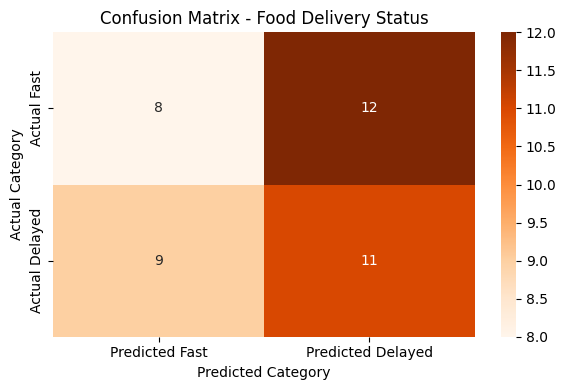

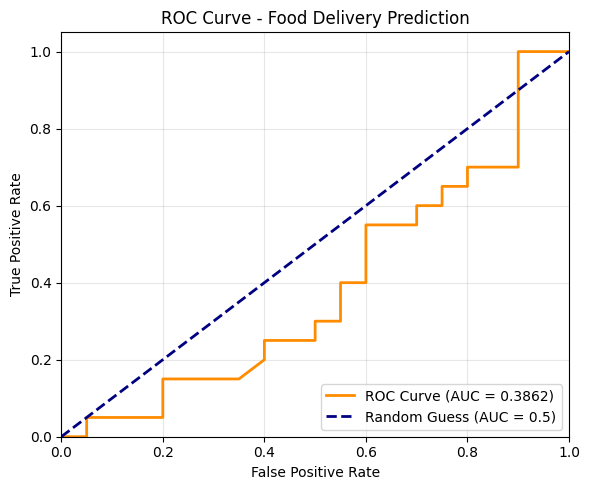

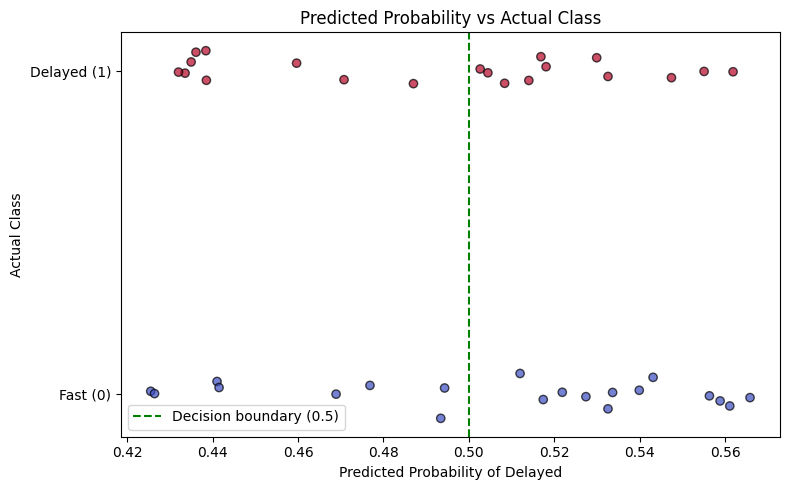

In [ ]:
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Predicted Fast', 'Predicted Delayed'],
            yticklabels=['Actual Fast', 'Actual Delayed'])
plt.title('Confusion Matrix - Food Delivery Status')
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.tight_layout()
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, proba)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Food Delivery Prediction')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

jitter = np.random.normal(0, 0.03, size=len(y_test))
plt.figure(figsize=(8, 5))
plt.scatter(proba, y_test.values + jitter, c=y_test.values, cmap='coolwarm', edgecolor='k', alpha=0.7)
plt.axvline(0.5, color='green', linestyle='--', label='Decision boundary (0.5)')
plt.yticks([0, 1], ['Fast (0)', 'Delayed (1)'])
plt.xlabel('Predicted Probability of Delayed')
plt.ylabel('Actual Class')
plt.title('Predicted Probability vs Actual Class')
plt.legend()
plt.tight_layout()
plt.show()

## 6. Conclusion & Limitations

In [ ]:
print("="*60)
print("CONCLUSION")
print("="*60)
print(f"""
The tuned Logistic Regression model achieved:
- Test Accuracy : {accuracy_score(y_test, pred):.4f}
- Test ROC AUC   : {roc_auc_score(y_test, proba):.4f}

For reference, a model that guesses randomly on this balanced
binary target would achieve ~0.50 accuracy and 0.50 ROC AUC.
Our model performed at or below this baseline, indicating that
the available features do not have a strong relationship with
Delivery_Time in this dataset.

This was cross-checked using:
- Correlation analysis: all features showed near-zero correlation
  (< 0.1 in magnitude) with Delivery_Time.
- 5-fold cross-validation: mean accuracy remained close to the
  random-guess baseline across folds, ruling out an unlucky
  train-test split as the cause.
- Hyperparameter tuning via GridSearchCV: the best configuration
  found (C={{grid.best_params_['C']}}, penalty={{grid.best_params_['penalty']}})
  still did not exceed baseline performance.

This suggests the dataset's Delivery_Time values are not strongly
determined by the given order, weather, traffic, or rating features,
which is consistent with the dataset appearing to be synthetically
or randomly generated rather than reflecting real-world delivery
dynamics. Despite this, the project demonstrates a complete and
correct machine learning workflow: data cleaning, EDA, encoding,
scaling, model training, hyperparameter tuning, multi-metric
evaluation, and local deployment via a Streamlit web application.
""")

CONCLUSION

The tuned Logistic Regression model achieved:
- Test Accuracy : 0.4750
- Test ROC AUC   : 0.3862

For reference, a model that guesses randomly on this balanced
binary target would achieve ~0.50 accuracy and 0.50 ROC AUC.
Our model performed at or below this baseline, indicating that
the available features do not have a strong relationship with
Delivery_Time in this dataset.

This was cross-checked using:
- Correlation analysis: all features showed near-zero correlation
  (< 0.1 in magnitude) with Delivery_Time.
- 5-fold cross-validation: mean accuracy remained close to the
  random-guess baseline across folds, ruling out an unlucky
  train-test split as the cause.
- Hyperparameter tuning via GridSearchCV: the best configuration
  found (C={grid.best_params_['C']}, penalty={grid.best_params_['penalty']})
  still did not exceed baseline performance.

This suggests the dataset's Delivery_Time values are not strongly
determined by the given order, weather, traffic, or rating fe

## 7. Deployment
The trained model was saved (`delivery_model.pkl`) along with its scaler and encoders, then deployed locally using a Streamlit web app (`app.py`) that takes order details as input and predicts delivery status in real time.